# Telco Customer Churn: LightGBM + XGBoost + CatBoost ensemble (Python)

**Competition:** [Playground Series S6E3, Predict Customer Churn](https://www.kaggle.com/competitions/playground-series-s6e3). Metric: ROC-AUC.

Plan:

1. Load the data and look at the main churn drivers
2. Add three engineered features
3. Train LightGBM, XGBoost and CatBoost with the same 5-fold stratified CV
4. Blend the three by weighted rank average, with weights chosen on out-of-fold predictions
5. Write the submission

The R version (tidymodels + XGBoost) and all the code live in [github.com/FelipeRamiresTerrazas/kaggle](https://github.com/FelipeRamiresTerrazas/kaggle).

In [1]:
import time
import warnings
from itertools import product
from pathlib import Path

import catboost as cb
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)

SEED = 42
N_FOLDS = 5

# The same notebook runs locally and on Kaggle.
ON_KAGGLE = Path("/kaggle/input").exists()
if ON_KAGGLE:
    DATA_DIR = next(Path("/kaggle/input").rglob("train.csv")).parent
    OUT_DIR = Path("/kaggle/working")
else:
    DATA_DIR = Path("../data")
    OUT_DIR = Path("../submissions")
    OUT_DIR.mkdir(exist_ok=True)

print("data:", DATA_DIR, "| lightgbm", lgb.__version__, "| xgboost", xgb.__version__, "| catboost", cb.__version__)

data: ..\data | lightgbm 4.7.0 | xgboost 3.4.1 | catboost 1.2.10


## 1. Data

In [2]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
print(f"train: {train.shape[0]:,} rows x {train.shape[1]} cols | test: {test.shape[0]:,} rows")
print("missing values:", int(train.isna().sum().sum() + test.isna().sum().sum()))
train["Churn"].value_counts(normalize=True).round(3)

train: 594,194 rows x 21 cols | test: 254,655 rows


missing values: 0


Churn
No     0.775
Yes    0.225
Name: proportion, dtype: float64

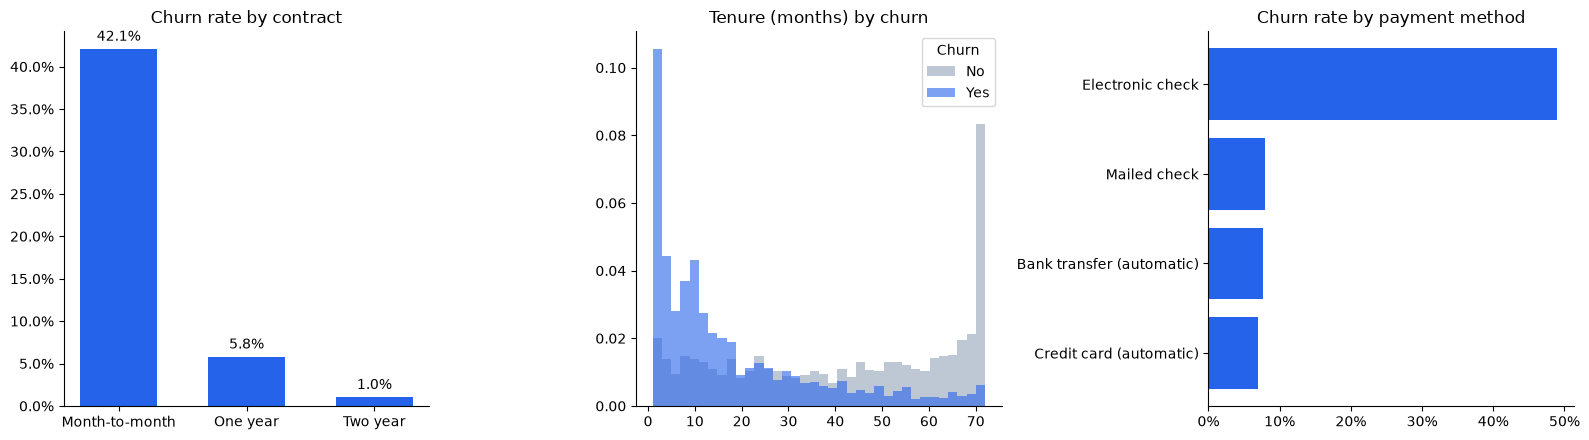

In [3]:
BLUE, GREY = "#2563eb", "#94a3b8"
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

rate = train.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean()).sort_values(ascending=False)
axes[0].bar(rate.index, rate.values, color=BLUE, width=0.6)
for i, v in enumerate(rate.values):
    axes[0].text(i, v + 0.01, f"{v:.1%}", ha="center")
axes[0].set_title("Churn rate by contract")
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))

for label, color in [("No", GREY), ("Yes", BLUE)]:
    axes[1].hist(train.loc[train["Churn"] == label, "tenure"], bins=36, density=True, alpha=0.6, color=color, label=label)
axes[1].set_title("Tenure (months) by churn")
axes[1].legend(title="Churn")

rate = train.groupby("PaymentMethod")["Churn"].apply(lambda s: (s == "Yes").mean()).sort_values()
axes[2].barh(rate.index, rate.values, color=BLUE)
axes[2].set_title("Churn rate by payment method")
axes[2].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 2. Features

Three engineered features:

- `avg_charge`: total charges per month of tenure
- `charge_gap`: how far total charges are from `tenure x MonthlyCharges` (picks up price changes)
- `n_services`: number of add-on services the customer has

Things I tried that did **not** help in CV, so they're left out: treating the numeric columns as categoricals (overfits), target encoding from the original IBM Telco dataset, and appending the original dataset to the training folds.

In [4]:
SERVICES = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
            "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]


def add_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["avg_charge"] = df["TotalCharges"] / df["tenure"].clip(lower=1)
    df["charge_gap"] = df["TotalCharges"] - df["tenure"] * df["MonthlyCharges"]
    df["n_services"] = (df[SERVICES] == "Yes").sum(axis=1)
    return df


y = (train["Churn"] == "Yes").astype(int).values
X = add_features(train.drop(columns=["id", "Churn"]))
X_test = add_features(test.drop(columns=["id"]))

CATS = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
for c in CATS:
    cats = sorted(set(X[c]) | set(X_test[c]))
    X[c] = pd.Categorical(X[c], categories=cats)
    X_test[c] = pd.Categorical(X_test[c], categories=cats)

# CatBoost wants plain strings for its categorical features
X_cb, X_test_cb = X.copy(), X_test.copy()
for c in CATS:
    X_cb[c] = X_cb[c].astype(str)
    X_test_cb[c] = X_test_cb[c].astype(str)

print(f"{X.shape[1]} features: {len(CATS)} categorical, {X.shape[1] - len(CATS)} numeric")

22 features: 15 categorical, 7 numeric


## 3. Models

Every model uses the same folds, so their out-of-fold (OOF) predictions can be compared and blended fairly. Early stopping runs on each validation fold, and test predictions are averaged over the 5 fold models.

In [5]:
folds = list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(X, y))
oof, test_pred, scores = {}, {}, {}


def run_cv(name, fit_predict):
    """fit_predict(train_idx, valid_idx) -> (valid_pred, test_pred, best_iteration)"""
    t0 = time.time()
    oof[name] = np.zeros(len(X))
    test_pred[name] = np.zeros(len(X_test))
    for k, (tr, va) in enumerate(folds):
        va_pred, te_pred, it = fit_predict(tr, va)
        oof[name][va] = va_pred
        test_pred[name] += te_pred / N_FOLDS
        print(f"  {name} fold {k}: AUC {roc_auc_score(y[va], va_pred):.5f} ({it} iters)")
    scores[name] = roc_auc_score(y, oof[name])
    print(f"{name} OOF AUC {scores[name]:.5f} in {(time.time() - t0) / 60:.1f} min\n")

In [6]:
LGB_PARAMS = dict(objective="binary", learning_rate=0.02, num_leaves=31, min_child_samples=100,
                  feature_fraction=0.7, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0,
                  cat_smooth=20, verbose=-1, seed=SEED)


def lgb_fit_predict(tr, va):
    model = lgb.train(LGB_PARAMS, lgb.Dataset(X.iloc[tr], y[tr]), num_boost_round=6000,
                      valid_sets=[lgb.Dataset(X.iloc[va], y[va])],
                      callbacks=[lgb.early_stopping(200, verbose=False)])
    it = model.best_iteration
    return model.predict(X.iloc[va], num_iteration=it), model.predict(X_test, num_iteration=it), it


run_cv("lightgbm", lgb_fit_predict)

  lightgbm fold 0: AUC 0.91626 (2305 iters)


  lightgbm fold 1: AUC 0.91718 (2193 iters)


  lightgbm fold 2: AUC 0.91675 (2329 iters)


  lightgbm fold 3: AUC 0.91774 (2406 iters)


  lightgbm fold 4: AUC 0.91501 (2000 iters)


lightgbm OOF AUC 0.91658 in 6.9 min



In [7]:
def xgb_fit_predict(tr, va):
    model = xgb.XGBClassifier(n_estimators=6000, learning_rate=0.03, max_depth=6, min_child_weight=5,
                              subsample=0.8, colsample_bytree=0.7, reg_lambda=1.0, tree_method="hist",
                              enable_categorical=True, max_cat_to_onehot=1, eval_metric="auc",
                              early_stopping_rounds=200, random_state=SEED)
    model.fit(X.iloc[tr], y[tr], eval_set=[(X.iloc[va], y[va])], verbose=False)
    return model.predict_proba(X.iloc[va])[:, 1], model.predict_proba(X_test)[:, 1], model.best_iteration


run_cv("xgboost", xgb_fit_predict)

  xgboost fold 0: AUC 0.91613 (1140 iters)


  xgboost fold 1: AUC 0.91714 (1013 iters)


  xgboost fold 2: AUC 0.91680 (1295 iters)


  xgboost fold 3: AUC 0.91783 (979 iters)


  xgboost fold 4: AUC 0.91495 (922 iters)
xgboost OOF AUC 0.91656 in 9.3 min



In [8]:
def cb_fit_predict(tr, va):
    model = cb.CatBoostClassifier(iterations=CB_ITERATIONS, learning_rate=CB_LR, depth=6, l2_leaf_reg=3,
                                  eval_metric="AUC", od_type="Iter", od_wait=200, random_seed=SEED, verbose=0,
                                  allow_writing_files=False)
    model.fit(X_cb.iloc[tr], y[tr], cat_features=CATS, eval_set=(X_cb.iloc[va], y[va]), use_best_model=True)
    return (model.predict_proba(X_cb.iloc[va])[:, 1], model.predict_proba(X_test_cb)[:, 1],
            model.get_best_iteration())


CB_ITERATIONS, CB_LR = 2500, 0.15
run_cv("catboost", cb_fit_predict)

  catboost fold 0: AUC 0.91605 (646 iters)


  catboost fold 1: AUC 0.91706 (719 iters)


  catboost fold 2: AUC 0.91652 (650 iters)


  catboost fold 3: AUC 0.91771 (834 iters)


  catboost fold 4: AUC 0.91468 (724 iters)


catboost OOF AUC 0.91640 in 47.6 min



## 4. Blend

AUC only cares about ranking, so the blend averages ranks instead of probabilities. The weights are picked by a small grid search on the OOF predictions. With 594k OOF rows this barely overfits, but I keep the grid coarse anyway.

In [9]:
names = list(oof)
oof_rank = {n: rankdata(oof[n]) / len(X) for n in names}
test_rank = {n: rankdata(test_pred[n]) / len(X_test) for n in names}

results = []
for w in product(range(0, 5), repeat=len(names)):
    if sum(w) == 0:
        continue
    blend = sum(wi * oof_rank[n] for wi, n in zip(w, names))
    results.append((roc_auc_score(y, blend), w))
results.sort(reverse=True)
best_auc, best_w = results[0]

summary = pd.DataFrame({"OOF AUC": scores}).sort_values("OOF AUC", ascending=False)
summary.loc["blend " + "/".join(map(str, best_w))] = best_auc
summary.round(5)

,OOF AUC
lightgbm,0.91658
xgboost,0.91656
catboost,0.91640
blend 3/3/3,0.91677


In [10]:
corr = pd.DataFrame(oof).corr(method="spearman").round(4)
print("Spearman correlation of OOF predictions (lower = more to gain from blending):")
corr

Spearman correlation of OOF predictions (lower = more to gain from blending):


,lightgbm,xgboost,catboost
lightgbm,1.0000,0.9981,0.9952
xgboost,0.9981,1.0000,0.9952
catboost,0.9952,0.9952,1.0000


## 5. Submission

In [11]:
blend_test = sum(wi * test_rank[n] for wi, n in zip(best_w, names)) / sum(best_w)
submission = pd.DataFrame({"id": test["id"], "Churn": blend_test})

assert len(submission) == len(test) and submission["Churn"].between(0, 1).all()
submission.to_csv(OUT_DIR / "submission.csv", index=False)
print(f"wrote {OUT_DIR / 'submission.csv'} with weights {dict(zip(names, best_w))}")
submission.head()

wrote ..\submissions\submission.csv with weights {'lightgbm': 3, 'xgboost': 3, 'catboost': 3}


,id,Churn
0,594194,0.510646
1,594195,0.008092
2,594196,0.554035
3,594197,0.164136
4,594198,0.811967
